# Experiment 1, annotated — induction heads in GPT-2 small

A walk-through of `01_induction_replication.py`, broken into inspectable steps.
Run the cells in order. The point is to look inside the tensors, not just get
the final number.

**The question:** can GPT-2 do the trick *"I have seen this before, let me copy
what followed it last time"*? And if so, which parts of it do that?


## 0. Setup

`HookedTransformer` is TransformerLens's wrapper around a normal transformer. It
behaves like the real model, but lets you attach hooks to read or overwrite any
intermediate activation.


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer

torch.set_grad_enabled(False)   # we are not training anything

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)


d:\claudeTrials\interp-induction-shapley\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
model = HookedTransformer.from_pretrained('gpt2', device=DEVICE)
model.eval()
print('loaded')


C:\Users\usuario\AppData\Local\Temp\ipykernel_29904\1719318204.py:1: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained('gpt2', device=DEVICE)
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8983.33it/s]


Loaded pretrained model gpt2 into HookedTransformer
loaded


## 1. What the architecture actually is

Every token becomes a vector of `d_model` numbers. That vector travels through
the model and each block **adds** to it rather than replacing it — the shared
channel is called the *residual stream*.

Each of the `n_layers` blocks contains attention (with `n_heads` parallel heads)
and an MLP. The MLP processes each position independently; **attention is the
only thing that moves information between positions**.


In [3]:
cfg = model.cfg
print(f'layers          : {cfg.n_layers}')
print(f'heads per layer : {cfg.n_heads}')
print(f'total heads     : {cfg.n_layers * cfg.n_heads}')
print(f'd_model         : {cfg.d_model}   (width of the residual stream)')
print(f'd_head          : {cfg.d_head}    (= d_model / n_heads)')
print(f'vocab           : {cfg.d_vocab}')
print()
print(f'parameters      : {sum(p.numel() for p in model.parameters()):,}')


layers          : 12
heads per layer : 12
total heads     : 144
d_model         : 768   (width of the residual stream)
d_head          : 64    (= d_model / n_heads)
vocab           : 50257

parameters      : 163,049,041


In [4]:
# The first block, printed. Note attn and mlp side by side.
print(model.blocks[0])


TransformerBlock(
  (ln1): LayerNormPre(
    (hook_scale): HookPoint(name='blocks.0.ln1.hook_scale')
    (hook_normalized): HookPoint(name='blocks.0.ln1.hook_normalized')
  )
  (ln2): LayerNormPre(
    (hook_scale): HookPoint(name='blocks.0.ln2.hook_scale')
    (hook_normalized): HookPoint(name='blocks.0.ln2.hook_normalized')
  )
  (attn): Attention(
    (hook_k): HookPoint(name='blocks.0.attn.hook_k')
    (hook_q): HookPoint(name='blocks.0.attn.hook_q')
    (hook_v): HookPoint(name='blocks.0.attn.hook_v')
    (hook_z): HookPoint(name='blocks.0.attn.hook_z')
    (hook_attn_scores): HookPoint(name='blocks.0.attn.hook_attn_scores')
    (hook_pattern): HookPoint(name='blocks.0.attn.hook_pattern')
    (hook_result): HookPoint(name='blocks.0.attn.hook_result')
  )
  (mlp): MLP(
    (hook_pre): HookPoint(name='blocks.0.mlp.hook_pre')
    (hook_post): HookPoint(name='blocks.0.mlp.hook_post')
  )
  (hook_attn_in): HookPoint(name='blocks.0.hook_attn_in')
  (hook_q_input): HookPoint(name='blocks

## 2. Build the prompt

`[BOS] + S + S`, where `S` is a run of uniformly random tokens.

- The **first copy** is unpredictable by construction — the tokens are random.
- The **second copy** is perfectly predictable *if* the model can look back.

That asymmetry is the whole design. Any drop in loss at the boundary has to come
from the model using the earlier occurrence.


In [5]:
SEQ_LEN = 50
BATCH   = 32
SEED    = 0

gen = torch.Generator().manual_seed(SEED)

bos   = torch.full((BATCH, 1), model.tokenizer.bos_token_id, dtype=torch.long)
block = torch.randint(0, cfg.d_vocab, (BATCH, SEQ_LEN), dtype=torch.long, generator=gen)
tokens = torch.cat([bos, block, block], dim=1).to(DEVICE)

print('shape:', tuple(tokens.shape), ' = BATCH x (1 + SEQ_LEN + SEQ_LEN)')


shape: (32, 101)  = BATCH x (1 + SEQ_LEN + SEQ_LEN)


Sanity check that it really is a repeat. Position `1+i` and position
`1+SEQ_LEN+i` must hold the same token.


In [6]:
row = tokens[0]
first  = row[1:1+SEQ_LEN]
second = row[1+SEQ_LEN:]
print('identical copies:', torch.equal(first, second))
print()
print('first 8 tokens of copy 1:', first[:8].tolist())
print('first 8 tokens of copy 2:', second[:8].tolist())
print()
print('as text (nonsense, as intended):')
print(repr(model.to_string(first[:8])))


identical copies: True

first 8 tokens of copy 1: [32487, 27591, 7093, 953, 10379, 5139, 38222, 10161]
first 8 tokens of copy 2: [32487, 27591, 7093, 953, 10379, 5139, 38222, 10161]

as text (nonsense, as intended):
' sexes spit magazine modfiletic McFEm'


## 3. Does the model do induction?

`loss_per_token[b, i]` is the cross-entropy for predicting position `i+1`.
So the array has `2*SEQ_LEN` columns, and **the second copy starts at column
`SEQ_LEN`** — worth checking by hand, since every later number depends on it.


In [7]:
loss_per_token = model(tokens, return_type='loss', loss_per_token=True)
print('shape:', tuple(loss_per_token.shape), ' = BATCH x 2*SEQ_LEN')

loss = loss_per_token.mean(dim=0).cpu().numpy()   # average over the batch

first_copy  = loss[:SEQ_LEN].mean()
second_copy = loss[SEQ_LEN:].mean()
print()
print(f'first copy  : {first_copy:6.3f} nats')
print(f'second copy : {second_copy:6.3f} nats')
print(f'drop        : {first_copy - second_copy:6.3f} nats')


shape: (32, 100)  = BATCH x 2*SEQ_LEN

first copy  : 13.183 nats
second copy :  0.536 nats
drop        : 12.647 nats


For scale: a loss of 13 nats means the model is assigning the correct token a
probability of about `exp(-13)` — effectively blind, which is right for random
tokens. A loss near 0.5 means it is nearly certain and nearly always correct.


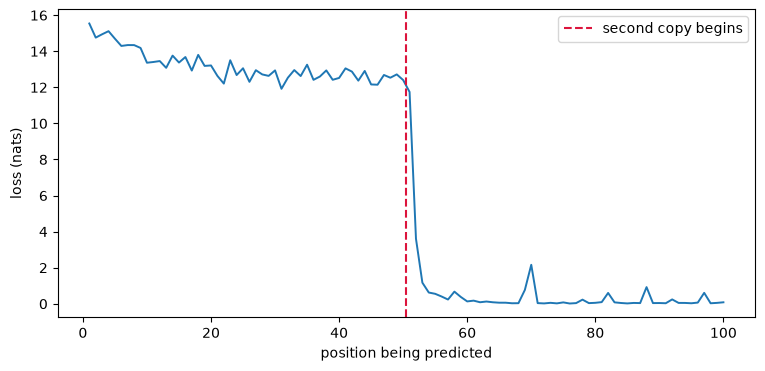

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, 2*SEQ_LEN + 1), loss, lw=1.4)
ax.axvline(SEQ_LEN + 0.5, color='crimson', ls='--', label='second copy begins')
ax.set_xlabel('position being predicted'); ax.set_ylabel('loss (nats)')
ax.legend(); plt.show()


Look at the shape of the drop. It is **not** a clean step — it takes three or
four positions to reach the floor. Only one of those is explained by there being
no prior occurrence to attend to yet. The rest is still unexplained (see NOTES.md).


## 4. Look inside: attention patterns

`run_with_cache` re-runs the model and keeps every intermediate activation.

The one we want is `pattern`: for each head, a matrix of
`[destination position, source position]` giving how much attention the
destination pays to the source. Rows sum to 1.


In [9]:
_, cache = model.run_with_cache(tokens)

pattern = cache['pattern', 5]   # attention patterns for all heads in layer 5
print('shape:', tuple(pattern.shape), ' = BATCH x n_heads x dest x src')
print()
print('row sums to 1?', pattern[0, 5, 60, :].sum().item())


shape: (32, 12, 101, 101)  = BATCH x n_heads x dest x src

row sums to 1? 0.9999998807907104


### The offset diagonal

Say we are at destination position `d`, inside the second copy, holding token
`S[j]`. The next token will be `S[j+1]`. Where did `S[j+1]` appear before?

```
d = 1 + SEQ_LEN + j          (current position)
S[j+1] first appeared at  1 + (j+1) = j + 2
d - SEQ_LEN + 1           = j + 2      <-- same place
```

So a head doing induction should attend from `d` to `d - SEQ_LEN + 1`: a fixed
offset of `SEQ_LEN - 1` positions back. In the attention matrix that is a single
diagonal line, at offset `1 - SEQ_LEN`.

Let us just look at it.


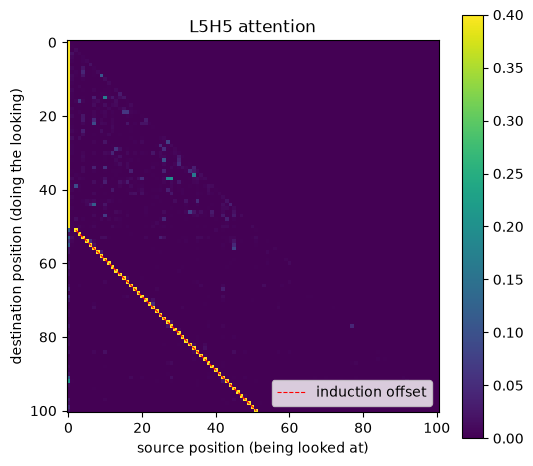

In [10]:
LAYER, HEAD = 5, 5      # top-scoring head from the full sweep

p = cache['pattern', LAYER][0, HEAD].cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(p, cmap='viridis', vmax=0.4)
ax.set_xlabel('source position (being looked at)')
ax.set_ylabel('destination position (doing the looking)')
ax.set_title(f'L{LAYER}H{HEAD} attention')

# overlay the induction diagonal
d = np.arange(SEQ_LEN + 1, 2*SEQ_LEN + 1)
ax.plot(d - SEQ_LEN + 1, d, color='red', lw=0.8, ls='--', label='induction offset')
ax.legend(loc='lower right')
plt.colorbar(im, ax=ax); plt.show()


The bright stripe should sit on the red dashed line. That is the head looking
back to exactly the right place, once the second copy starts.


## 5. Turn that into a number

`torch.diagonal` with `offset=1-SEQ_LEN` pulls out precisely that line. Average
it, and you have the head's *induction score*.

Do it for one head first, by hand, so the vectorised version below is checkable.


In [11]:
diag = pattern.diagonal(offset=1 - SEQ_LEN, dim1=-2, dim2=-1)
print('diagonal shape:', tuple(diag.shape), ' = BATCH x n_heads x len(diagonal)')
print()
print(f'L5H5  induction score: {diag[:, 5, :].mean().item():.3f}')
print(f'L5H0  induction score: {diag[:, 0, :].mean().item():.3f}')
print()
print('(1.0 would mean all attention on the induction position)')


diagonal shape: (32, 12, 52)  = BATCH x n_heads x len(diagonal)

L5H5  induction score: 0.907
L5H0  induction score: 0.451

(1.0 would mean all attention on the induction position)


## 6. All 144 heads


In [12]:
scores = torch.zeros(cfg.n_layers, cfg.n_heads)
for layer in range(cfg.n_layers):
    pat = cache['pattern', layer]
    d = pat.diagonal(offset=1 - SEQ_LEN, dim1=-2, dim2=-1)
    scores[layer] = d.mean(dim=(0, -1)).cpu()

top = torch.topk(scores.flatten(), k=10)
print('rank  head     score')
for r, (v, i) in enumerate(zip(top.values.tolist(), top.indices.tolist()), 1):
    l, h = divmod(i, cfg.n_heads)
    print(f'{r:4d}  L{l}H{h:<4}  {v:.3f}')


rank  head     score
   1  L5H5     0.907
   2  L6H9     0.891
   3  L5H1     0.889
   4  L7H10    0.888
   5  L7H2     0.814
   6  L10H1     0.509
   7  L9H6     0.504
   8  L9H9     0.494
   9  L10H7     0.462
  10  L5H0     0.451


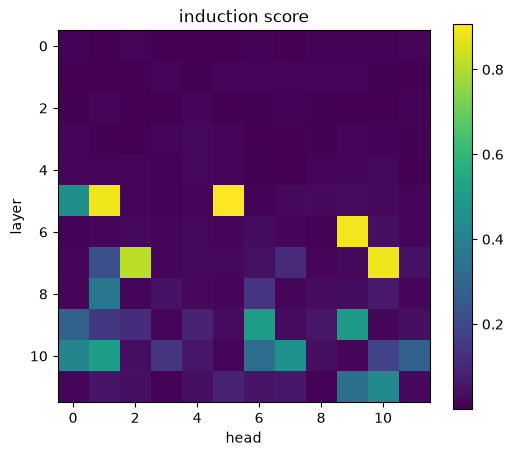

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(scores.numpy(), cmap='viridis')
ax.set_xlabel('head'); ax.set_ylabel('layer')
ax.set_title('induction score')
plt.colorbar(im, ax=ax); plt.show()


Notice the scores fall into **two groups**, not a smooth gradient: five heads
around 0.81-0.91, a gap, then a cluster around 0.45-0.51. What the second group
is doing is an open question.


## 7. The other half of the circuit: previous-token heads

An induction head cannot work on its own.

For the second `gato` at position `d` to ask *"who here has a `gato`
immediately before them?"*, something must already have written *"my previous
token was `gato`"* into the residual stream at the position being looked at.

That is the job of a **previous-token head** in an earlier layer. It does
something very simple: from every position, attend to the one immediately
before it, and copy that information forward.

```
early layer   previous-token head  ->  writes "my predecessor was X"
layer 5-7     induction head       ->  reads that, matches, copies X's successor
```

This is called **composition**: two heads in different layers communicating
through the residual stream. Neither does the job alone.

Finding them uses exactly the same trick as before, with a different offset.
Induction looked back a whole copy (`1 - SEQ_LEN`). A previous-token head looks
back exactly one position, so the offset is `-1`.


In [14]:
prev_scores = torch.zeros(cfg.n_layers, cfg.n_heads)
for layer in range(cfg.n_layers):
    pat = cache['pattern', layer]
    d = pat.diagonal(offset=-1, dim1=-2, dim2=-1)   # src = dest - 1
    prev_scores[layer] = d.mean(dim=(0, -1)).cpu()

top_prev = torch.topk(prev_scores.flatten(), k=10)
print('rank  head     prev-token score')
for r, (v, i) in enumerate(zip(top_prev.values.tolist(), top_prev.indices.tolist()), 1):
    l, h = divmod(i, cfg.n_heads)
    print(f'{r:4d}  L{l}H{h:<4}  {v:.3f}')


rank  head     prev-token score
   1  L4H11    0.989
   2  L3H7     0.541
   3  L6H8     0.508
   4  L2H2     0.483
   5  L5H6     0.422
   6  L3H2     0.411
   7  L2H9     0.371
   8  L3H8     0.365
   9  L2H5     0.350
  10  L3H6     0.337


### Where do the two kinds of head live?

If the composition story is right, previous-token heads should sit in **earlier**
layers than induction heads, they have to write before the induction head can
read.


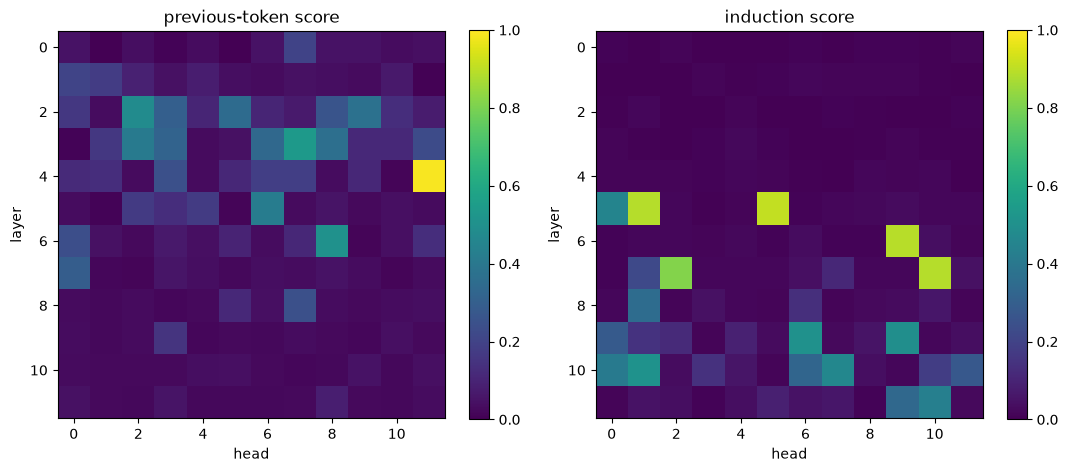

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (mat, name) in zip(axes, [(prev_scores, 'previous-token'),
                                  (scores,      'induction')]):
    im = ax.imshow(mat.numpy(), cmap='viridis', vmin=0, vmax=1)
    ax.set_xlabel('head'); ax.set_ylabel('layer')
    ax.set_title(f'{name} score')
    plt.colorbar(im, ax=ax)

plt.tight_layout(); plt.show()


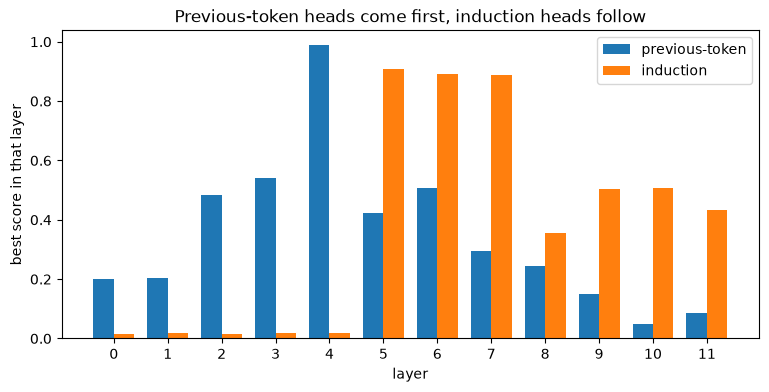

In [16]:
# Strongest head of each type, layer by layer.
layers = np.arange(cfg.n_layers)
w = 0.38

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(layers - w/2, prev_scores.max(dim=1).values.numpy(), w, label='previous-token')
ax.bar(layers + w/2, scores.max(dim=1).values.numpy(),      w, label='induction')
ax.set_xlabel('layer'); ax.set_ylabel('best score in that layer')
ax.set_xticks(layers)
ax.set_title('Previous-token heads come first, induction heads follow')
ax.legend(); plt.show()


### What a previous-token head looks like

Its attention pattern should be a single clean line one step below the main
diagonal, running the whole length of the sequence, including the first copy,
where induction heads do nothing.

Zoomed to the first 25 positions, otherwise the line is one pixel wide.


strongest previous-token head: L4H11  (0.989)


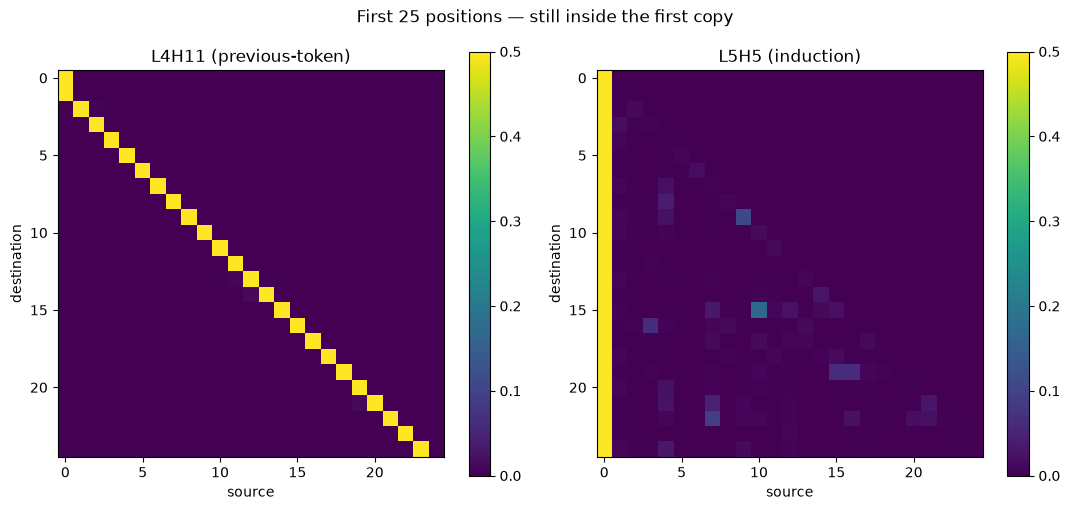

In [17]:
i = int(torch.argmax(prev_scores).item())
PL, PH = divmod(i, cfg.n_heads)
print(f'strongest previous-token head: L{PL}H{PH}  ({prev_scores[PL, PH]:.3f})')

N = 25
p_prev = cache['pattern', PL][0, PH, :N, :N].cpu().numpy()
p_ind  = cache['pattern', LAYER][0, HEAD, :N, :N].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (p, title) in zip(axes, [(p_prev, f'L{PL}H{PH} (previous-token)'),
                                 (p_ind,  f'L{LAYER}H{HEAD} (induction)')]):
    im = ax.imshow(p, cmap='viridis', vmax=0.5)
    ax.set_xlabel('source'); ax.set_ylabel('destination')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
plt.suptitle('First 25 positions — still inside the first copy')
plt.tight_layout(); plt.show()


The contrast is the point. In this window the previous-token head is already
working — a steady line just under the diagonal. The induction head has nothing
to do yet, because no token has repeated. It only activates once the second copy
begins.

### Why this matters for ablation

If the behaviour lives in a **circuit spanning heads and layers**, rather than
inside any single head, then knocking out one head should be uninformative, the
function was never located there in the first place.

That is the mechanistic reason behind the experiment 2 result: 85-97% of the
joint effect turned out to be interaction, and single-head ablation saw almost
none of it.

It also raises a question the ablation experiment did not test: the five heads
ablated there were all induction heads. **The previous-token heads were left
intact.** Ablating across both halves of the circuit is a different experiment,
and not one that has been run yet.


## 8. A test that can fail

Everything up to here has been **confirmatory**. We predicted induction heads in
the middle layers and found them; we predicted previous-token heads earlier and
found those too. The prior was already high, so passing those checks says little
beyond "the measurement works".

This section is different. The composition story makes a prediction that could
come out wrong:

> L4H11 scores 0.989 and the next previous-token head only 0.541. If the circuit
> really runs *previous-token head → induction head*, and if that first stage has
> no real backup, then **ablating L4H11 alone should break induction**,  even
> though ablating any single induction head barely does anything.

If L4H11 turns out to be as replaceable as the induction heads were, the story is
wrong or incomplete.

*Note: this notebook uses `BATCH=32`, while `02_ablation_shapley.py` used 64, so
numbers here will be close to but not identical to the script's.*


In [18]:
# Ablation machinery. Same three counterfactuals as experiment 2.

perm = torch.roll(torch.arange(BATCH, device=DEVICE), shifts=1)

def ablate_hook(head_idx, mode, mean_z=None):
    def hook(z, hook):          # z: [batch, pos, head, d_head]
        if mode == 'zero':
            z[:, :, head_idx, :] = 0.0
        elif mode == 'mean':
            z[:, :, head_idx, :] = mean_z
        elif mode == 'resample':
            z[:, :, head_idx, :] = z[perm, :, head_idx, :]
        return z
    return hook

def build(heads, mode):
    hooks = []
    for (l, h) in heads:
        mz = cache['z', l][:, :, h, :].mean(dim=(0, 1)) if mode == 'mean' else None
        hooks.append((f'blocks.{l}.attn.hook_z', ablate_hook(h, mode, mz)))
    return hooks

def loss_ablated(heads, mode='zero'):
    if not heads:
        lpt = model(tokens, return_type='loss', loss_per_token=True)
    else:
        lpt = model.run_with_hooks(tokens, return_type='loss', loss_per_token=True,
                                   fwd_hooks=build(heads, mode))
    return lpt[:, SEQ_LEN:].mean().item()

clean = loss_ablated([])
print(f'clean second-copy loss: {clean:.4f} nats')


clean second-copy loss: 0.5362 nats


### The comparison

One previous-token head against five induction heads, each alone, and all five
together.


In [19]:
IND_HEADS = [(5,5), (6,9), (5,1), (7,10), (7,2)]
PREV_HEAD = (PL, PH)          # L4H11, found in section 7

# a control: the weakest previous-token head in the same layer as L4H11
ctrl_head = (PL, int(torch.argmin(prev_scores[PL]).item()))
print(f'control head (same layer, lowest prev-token score): '
      f'L{ctrl_head[0]}H{ctrl_head[1]}  ({prev_scores[ctrl_head]:.3f})')
print()

rows = []
for mode in ['zero', 'mean', 'resample']:
    r = {
        'mode': mode,
        f'L{PL}H{PH} (prev-tok)': loss_ablated([PREV_HEAD], mode) - clean,
        f'L{ctrl_head[0]}H{ctrl_head[1]} (control)': loss_ablated([ctrl_head], mode) - clean,
        'best single induction': max(loss_ablated([h], mode) - clean for h in IND_HEADS),
        'all 5 induction': loss_ablated(IND_HEADS, mode) - clean,
    }
    rows.append(r)

hdr = list(rows[0].keys())
print(f"{hdr[0]:<10}" + ''.join(f'{h:>26}' for h in hdr[1:]))
for r in rows:
    print(f"{r['mode']:<10}" + ''.join(f'{r[h]:>+26.4f}' for h in hdr[1:]))
print()
print('(values are increase in second-copy loss, in nats)')


control head (same layer, lowest prev-token score): L4H10  (0.015)

mode                L4H11 (prev-tok)           L4H10 (control)     best single induction           all 5 induction
zero                         +0.2498                   +0.0090                   +0.6122                   +4.7872
mean                         +0.2495                   +0.0029                   +0.6324                   +5.0681
resample                     +0.7356                   -0.0008                   +0.1159                  +11.5246

(values are increase in second-copy loss, in nats)


### The mechanistic check

A loss number tells you *that* something broke. The prediction is more specific
than that: with L4H11 gone, the induction heads should no longer be able to find
the right position, because the information they match against is missing.

So measure their **induction scores** again with L4H11 ablated. If the story is
right, the attention patterns themselves should degrade, not just the loss.


In [20]:
def induction_scores_under_ablation(heads, mode='zero'):
    with model.hooks(fwd_hooks=build(heads, mode)):
        _, c = model.run_with_cache(tokens)
    out = {}
    for (l, h) in IND_HEADS:
        d = c['pattern', l].diagonal(offset=1 - SEQ_LEN, dim1=-2, dim2=-1)
        out[(l, h)] = d[:, h, :].mean().item()
    del c
    return out

base   = {h: scores[h[0], h[1]].item() for h in IND_HEADS}
no_prev = induction_scores_under_ablation([PREV_HEAD], 'zero')
no_ctrl = induction_scores_under_ablation([ctrl_head], 'zero')

print(f"{'head':>8}{'clean':>10}{'L'+str(PL)+'H'+str(PH)+' abl':>14}{'control abl':>14}")
for h in IND_HEADS:
    print(f'  L{h[0]}H{h[1]:<4}{base[h]:>10.3f}{no_prev[h]:>14.3f}{no_ctrl[h]:>14.3f}')


    head     clean     L4H11 abl   control abl
  L5H5        0.907         0.673         0.907
  L6H9        0.891         0.831         0.892
  L5H1        0.889         0.537         0.887
  L7H10       0.888         0.775         0.883
  L7H2        0.814         0.672         0.804


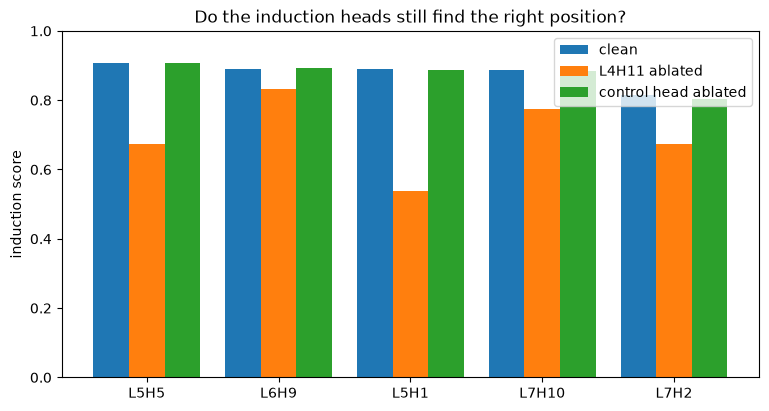

In [21]:
labels = [f'L{l}H{h}' for l, h in IND_HEADS]
x = np.arange(len(IND_HEADS)); w = 0.27

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, [base[h] for h in IND_HEADS], w, label='clean')
ax.bar(x,     [no_prev[h] for h in IND_HEADS], w, label=f'L{PL}H{PH} ablated')
ax.bar(x + w, [no_ctrl[h] for h in IND_HEADS], w, label='control head ablated')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('induction score'); ax.set_ylim(0, 1)
ax.set_title('Do the induction heads still find the right position?')
ax.legend(); plt.show()


### 8b. If the previous-token role is redundant, take out the whole stage

L4H11 alone was not enough. The obvious follow-up: remove previous-token
capacity **cumulatively**, strongest first, and watch where induction gives way.

Two things to keep in mind while reading this.

**Layer order constrains what can matter.** The residual stream only flows
forward, so a previous-token head in layer 6 cannot feed an induction head in
layer 5. L6H8 is in the list by score, but it can only be relevant to L7H10 and
L7H2, never to L5H5 or L5H1.

**A matched control is needed.** Ablating six heads might degrade the model for
reasons that have nothing to do with the previous-token role. So the same number
of heads is ablated from the same layers, chosen for the *lowest* previous-token
scores. If the two curves separate, the effect is about the role and not the
count.


In [22]:
k_max = 6
flat = torch.topk(prev_scores.flatten(), k=k_max)
prev_top = [divmod(i, cfg.n_heads) for i in flat.indices.tolist()]
print('previous-token heads, strongest first:')
for (l, h), v in zip(prev_top, flat.values.tolist()):
    print(f'  L{l}H{h:<3} {v:.3f}   (layer {l})')
# Matched control: same layers, lowest previous-token score in each --
# BUT excluding heads that are themselves doing induction. A first attempt
# without that filter picked L6H9 and L5H1, which are induction heads: they
# score low on previous-token because they do not attend to i-1, and ablating
# them contaminated the control with the very effect being controlled for.
ctrl_top = []
for (l, _) in prev_top:
    order = torch.argsort(prev_scores[l])
    for idx in order.tolist():
        if (l, idx) in ctrl_top:
            continue
        if scores[l, idx] > 0.3:          # skip anything doing induction
            continue
        ctrl_top.append((l, idx)); break
print()
print('matched control (same layers, weak prev-token AND weak induction):')
for (l, h) in ctrl_top:
    print(f'  L{l}H{h:<3} prev {prev_scores[l, h]:.3f}  ind {scores[l, h]:.3f}')


previous-token heads, strongest first:
  L4H11  0.989   (layer 4)
  L3H7   0.541   (layer 3)
  L6H8   0.508   (layer 6)
  L2H2   0.483   (layer 2)
  L5H6   0.422   (layer 5)
  L3H2   0.411   (layer 3)

matched control (same layers, weak prev-token AND weak induction):
  L4H10  prev 0.015  ind 0.018
  L3H0   prev 0.011  ind 0.013
  L6H2   prev 0.024  ind 0.018
  L2H1   prev 0.032  ind 0.017
  L5H9   prev 0.026  ind 0.028
  L3H4   prev 0.028  ind 0.020


In [23]:
def mean_induction_score(heads, mode='zero'):
    if heads:
        with model.hooks(fwd_hooks=build(heads, mode)):
            _, c = model.run_with_cache(tokens)
    else:
        _, c = model.run_with_cache(tokens)
    vals = []
    for (l, h) in IND_HEADS:
        d = c['pattern', l].diagonal(offset=1 - SEQ_LEN, dim1=-2, dim2=-1)
        vals.append(d[:, h, :].mean().item())
    del c
    return float(np.mean(vals))

ks = list(range(k_max + 1))
curves = {}
for name, pool in [('previous-token', prev_top), ('matched control', ctrl_top)]:
    L, S = [], []
    for k in ks:
        subset = pool[:k]
        L.append(loss_ablated(subset, 'zero'))
        S.append(mean_induction_score(subset, 'zero'))
    curves[name] = {'loss': L, 'score': S}
    print(f'{name}:')
    for k, (l_, s_) in enumerate(zip(L, S)):
        who = ','.join(f'L{a}H{b}' for a, b in pool[:k]) or '(none)'
        print(f'  k={k}  loss {l_:7.3f}   mean induction {s_:.3f}   {who}')
    print()


previous-token:
  k=0  loss   0.536   mean induction 0.878   (none)
  k=1  loss   0.786   mean induction 0.698   L4H11
  k=2  loss   0.948   mean induction 0.630   L4H11,L3H7
  k=3  loss   0.978   mean induction 0.622   L4H11,L3H7,L6H8
  k=4  loss   1.327   mean induction 0.550   L4H11,L3H7,L6H8,L2H2
  k=5  loss   2.143   mean induction 0.429   L4H11,L3H7,L6H8,L2H2,L5H6
  k=6  loss   2.422   mean induction 0.417   L4H11,L3H7,L6H8,L2H2,L5H6,L3H2

matched control:
  k=0  loss   0.536   mean induction 0.878   (none)
  k=1  loss   0.545   mean induction 0.875   L4H10
  k=2  loss   0.599   mean induction 0.849   L4H10,L3H0
  k=3  loss   0.655   mean induction 0.845   L4H10,L3H0,L6H2
  k=4  loss   0.658   mean induction 0.844   L4H10,L3H0,L6H2,L2H1
  k=5  loss   1.335   mean induction 0.790   L4H10,L3H0,L6H2,L2H1,L5H9
  k=6  loss   1.816   mean induction 0.781   L4H10,L3H0,L6H2,L2H1,L5H9,L3H4



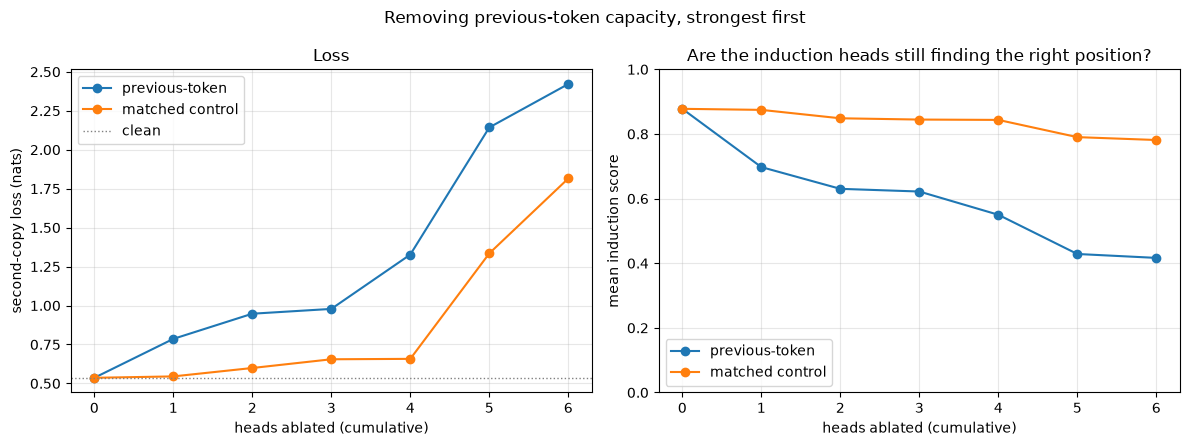

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, c in curves.items():
    axes[0].plot(ks, c['loss'],  marker='o', label=name)
    axes[1].plot(ks, c['score'], marker='o', label=name)

axes[0].axhline(clean, color='grey', ls=':', lw=1, label='clean')
axes[0].set_xlabel('heads ablated (cumulative)')
axes[0].set_ylabel('second-copy loss (nats)')
axes[0].set_title('Loss')

axes[1].set_xlabel('heads ablated (cumulative)')
axes[1].set_ylabel('mean induction score')
axes[1].set_ylim(0, 1)
axes[1].set_title('Are the induction heads still finding the right position?')

for a in axes:
    a.legend(); a.grid(alpha=0.3)
plt.suptitle('Removing previous-token capacity, strongest first')
plt.tight_layout(); plt.show()


### For reference: how big is 'broken'?

The scale that matters is the induction effect itself. Clean second-copy loss is
about 0.54 nats; first-copy loss — the model with no usable information at all —
is about 13. Ablating all five induction heads cost roughly 4.8.

So the question for the curve above is whether removing previous-token capacity
gets anywhere near that 4.8, or stalls well short of it.


In [25]:
print(f'clean second-copy loss        : {clean:8.3f}')
print(f'all 5 induction heads ablated : {loss_ablated(IND_HEADS, "zero"):8.3f}')
print(f'{k_max} previous-token heads ablated : '
      f'{curves["previous-token"]["loss"][-1]:8.3f}')
print(f'first-copy loss (no info)     : {float(loss[:SEQ_LEN].mean()):8.3f}')


clean second-copy loss        :    0.536
all 5 induction heads ablated :    5.323
6 previous-token heads ablated :    2.422
first-copy loss (no info)     :   13.183


### 8c. Where is the breakpoint?

Six heads were not enough. So how much previous-token capacity has to go before
induction actually fails — and is there a sharp threshold at all, or does it just
erode?

Two design points that matter at larger `k`:

**Induction heads are excluded from the ablation pool.** L5H6 ranked fifth by
previous-token score, and further down the list more induction heads appear. If
they were ablated here we would be removing both stages of the circuit at once
and could not attribute the damage to either.

**The control carries most of the weight now.** Ablating 20 heads degrades the
model whatever those heads do. The quantity of interest is therefore not the
previous-token curve itself but its **separation from the matched control** — the
damage that is specific to the role rather than to the head count.


In [26]:
K_MAX = 24
IND_SET = set(IND_HEADS)

# Previous-token pool, strongest first, induction heads excluded.
order = torch.argsort(prev_scores.flatten(), descending=True).tolist()
prev_pool = []
for i in order:
    lh = divmod(i, cfg.n_heads)
    if lh in IND_SET:
        continue
    prev_pool.append(lh)
    if len(prev_pool) == K_MAX:
        break

# Matched control: same layer as each pool member, weak on both roles, unused.
ctrl_pool = []
for (l, _) in prev_pool:
    cand = torch.argsort(prev_scores[l]).tolist()
    for idx in cand:
        lh = (l, idx)
        if lh in ctrl_pool or lh in IND_SET or scores[l, idx] > 0.3:
            continue
        ctrl_pool.append(lh); break

print(f'{"k":>3}  {"prev-token":<12} {"score":>6}   {"control":<10} {"score":>6}')
for k, ((pl, ph), (cl, ch)) in enumerate(zip(prev_pool, ctrl_pool), 1):
    print(f'{k:>3}  L{pl}H{ph:<10} {prev_scores[pl,ph]:>6.3f}   '
          f'L{cl}H{ch:<8} {prev_scores[cl,ch]:>6.3f}')


  k  prev-token    score   control     score
  1  L4H11          0.989   L4H10        0.015
  2  L3H7           0.541   L3H0         0.011
  3  L6H8           0.508   L6H2         0.024
  4  L2H2           0.483   L2H1         0.032
  5  L5H6           0.422   L5H9         0.026
  6  L3H2           0.411   L3H4         0.028
  7  L2H9           0.371   L2H7         0.070
  8  L3H8           0.365   L3H5         0.045
  9  L2H5           0.350   L2H11        0.075
 10  L3H6           0.337   L3H9         0.114
 11  L3H3           0.320   L3H10        0.115
 12  L2H3           0.303   L2H6         0.102
 13  L7H0           0.296   L7H1         0.018
 14  L2H8           0.259   L2H4         0.105
 15  L4H3           0.246   L4H4         0.029
 16  L8H7           0.244   L8H3         0.019
 17  L6H0           0.241   L6H6         0.035
 18  L3H11          0.230   L3H1         0.163
 19  L1H0           0.205   L1H11        0.008
 20  L0H7           0.202   L0H1         0.001
 21  L4H7      

In [27]:
first_copy_loss = float(loss[:SEQ_LEN].mean())

ks = list(range(0, K_MAX + 1))
res = {'previous-token': {'loss': [], 'score': []},
       'control':        {'loss': [], 'score': []}}

for k in ks:
    for name, pool in [('previous-token', prev_pool), ('control', ctrl_pool)]:
        sub = pool[:k]
        res[name]['loss'].append(loss_ablated(sub, 'zero'))
        res[name]['score'].append(mean_induction_score(sub, 'zero'))

print(f'{"k":>3} {"prev loss":>10} {"ctrl loss":>10} {"gap":>8}   '
      f'{"prev ind":>9} {"ctrl ind":>9} {"gap":>8}')
for k in ks:
    pl_, cl_ = res['previous-token']['loss'][k],  res['control']['loss'][k]
    ps_, cs_ = res['previous-token']['score'][k], res['control']['score'][k]
    print(f'{k:>3} {pl_:>10.3f} {cl_:>10.3f} {pl_-cl_:>8.3f}   '
          f'{ps_:>9.3f} {cs_:>9.3f} {ps_-cs_:>8.3f}')


  k  prev loss  ctrl loss      gap    prev ind  ctrl ind      gap
  0      0.536      0.536    0.000       0.878     0.878    0.000
  1      0.786      0.545    0.241       0.698     0.875   -0.177
  2      0.948      0.599    0.348       0.630     0.849   -0.218
  3      0.978      0.655    0.323       0.622     0.845   -0.223
  4      1.327      0.658    0.669       0.550     0.844   -0.294
  5      2.143      1.335    0.808       0.429     0.790   -0.362
  6      2.422      1.816    0.606       0.417     0.781   -0.365
  7      4.956      1.979    2.977       0.284     0.772   -0.488
  8      5.356      2.660    2.696       0.266     0.744   -0.478
  9      5.533      2.964    2.570       0.254     0.725   -0.471
 10      6.198      3.038    3.159       0.229     0.720   -0.491
 11      8.072      2.892    5.180       0.136     0.704   -0.568
 12      8.107      3.710    4.397       0.135     0.651   -0.516
 13      8.267      3.987    4.280       0.135     0.651   -0.516
 14      8

In [28]:
clean_score = res['previous-token']['score'][0]

print(f'clean induction score : {clean_score:.3f}')
print(f'clean loss            : {clean:.3f}')
print(f'first-copy loss       : {first_copy_loss:.3f}   (no usable information)')
print()

def first_k(pred, label):
    for k in ks:
        if pred(k):
            print(f'{label:<46} k = {k}')
            return k
    print(f'{label:<46} not reached by k = {K_MAX}')
    return None

s = res['previous-token']['score']; l_ = res['previous-token']['loss']
first_k(lambda k: s[k] < 0.5 * clean_score,  'induction score halved')
first_k(lambda k: s[k] < 0.2,                'induction score below 0.2')
first_k(lambda k: s[k] < 0.1,                'induction score below 0.1')
first_k(lambda k: l_[k] > clean + 0.5 * (first_copy_loss - clean),
        'loss halfway to no-information')
print()
gaps = [res['previous-token']['loss'][k] - res['control']['loss'][k] for k in ks]
kmax_gap = int(np.argmax(gaps))
print(f'largest role-specific loss gap: {gaps[kmax_gap]:+.3f} nats at k = {kmax_gap}')


clean induction score : 0.878
clean loss            : 0.536
first-copy loss       : 13.183   (no usable information)

induction score halved                         k = 5
induction score below 0.2                      k = 11
induction score below 0.1                      k = 15
loss halfway to no-information                 k = 11

largest role-specific loss gap: +5.201 nats at k = 16


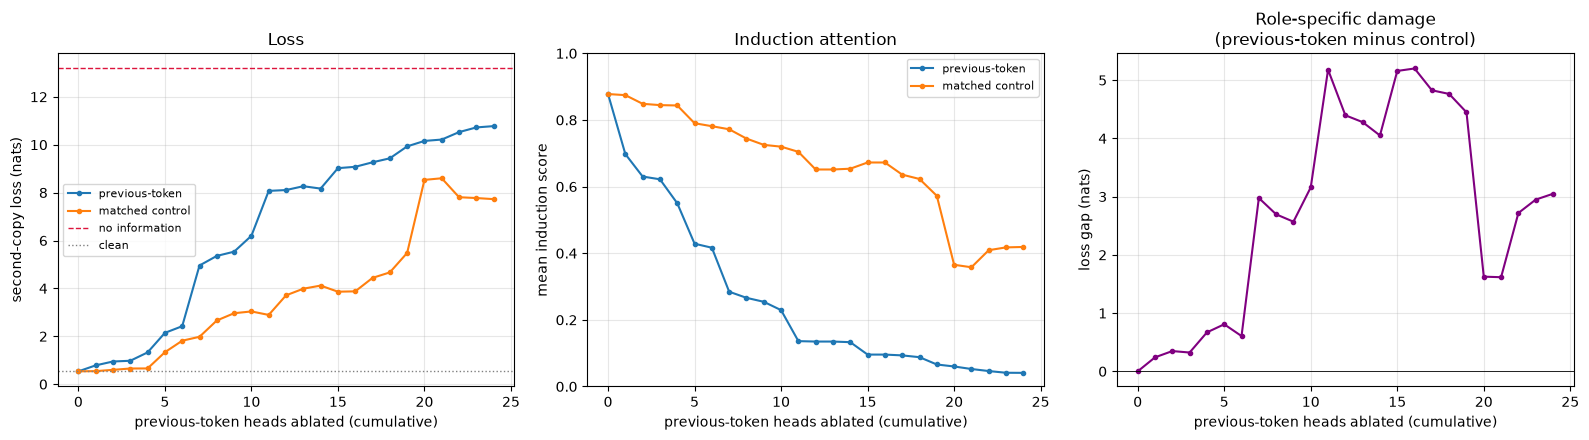

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(ks, res['previous-token']['loss'], marker='o', ms=3, label='previous-token')
axes[0].plot(ks, res['control']['loss'],        marker='o', ms=3, label='matched control')
axes[0].axhline(first_copy_loss, color='crimson', ls='--', lw=1, label='no information')
axes[0].axhline(clean, color='grey', ls=':', lw=1, label='clean')
axes[0].set_ylabel('second-copy loss (nats)'); axes[0].set_title('Loss')

axes[1].plot(ks, res['previous-token']['score'], marker='o', ms=3, label='previous-token')
axes[1].plot(ks, res['control']['score'],        marker='o', ms=3, label='matched control')
axes[1].set_ylim(0, 1); axes[1].set_ylabel('mean induction score')
axes[1].set_title('Induction attention')

axes[2].plot(ks, gaps, marker='o', ms=3, color='purple')
axes[2].axhline(0, color='k', lw=0.6)
axes[2].set_ylabel('loss gap (nats)')
axes[2].set_title('Role-specific damage\n(previous-token minus control)')

for a in axes:
    a.set_xlabel('previous-token heads ablated (cumulative)')
    a.grid(alpha=0.3)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


### What happened

Erosion, not a cliff. Six previous-token heads take the loss from 0.54 to 2.42
and the mean induction score from 0.878 to 0.417 — degraded, but far from broken,
and nowhere near the 4.8 that removing the induction heads costs.

The control earns its place here. Ablating six *matched* heads costs 1.28 nats by
itself, so only about 0.6 of the 1.89 is specific to the previous-token role.
Without the comparison the effect would look three times larger than it is.

Six was not enough to locate a threshold, so 8c extends the sweep.


### 8d. Control 1 — is L2H9 special, or is position 7 special?

Adding L2H9 seventh cost +2.5 nats, the largest single step in the sweep, even
though it ranks only seventh by previous-token score. Two explanations:

1. **The head is special** — L2H9 does something the others do not.
2. **The position is special** — by the seventh removal the redundancy is spent,
   and whichever head went in seventh would have cost about the same.

Two tests. First, ablate each of the top twelve **alone**: if L2H9 is special it
should stand out in isolation. Second, run the cumulative sweep under several
**random orderings**: if the big jump tracks position rather than identity, the
curves will lie on top of each other regardless of which head goes where.


In [30]:
pool12 = prev_pool[:12]

solo = {h: loss_ablated([h], 'zero') - clean for h in pool12}
print('ablated alone, in isolation:')
print(f"{'rank':>4}  {'head':<7}{'prev score':>11}{'alone':>9}")
for r, h in enumerate(pool12, 1):
    mark = '   <-- the k=7 head' if h == pool12[6] else ''
    print(f'{r:>4}  L{h[0]}H{h[1]:<4}{prev_scores[h]:>11.3f}{solo[h]:>+9.3f}{mark}')


ablated alone, in isolation:
rank  head    prev score    alone
   1  L4H11        0.989   +0.250
   2  L3H7         0.541   +0.004
   3  L6H8         0.508   -0.014
   4  L2H2         0.483   -0.011
   5  L5H6         0.422   +0.003
   6  L3H2         0.411   +0.028
   7  L2H9         0.371   +0.065   <-- the k=7 head
   8  L3H8         0.365   +0.006
   9  L2H5         0.350   +0.025
  10  L3H6         0.337   +0.016
  11  L3H3         0.320   +0.008
  12  L2H3         0.303   +0.085


If L2H9's solo effect looks like everyone else's, explanation 2 is already ahead.


In [31]:
import random

N_ORDERS = 8
rng = random.Random(0)
ks12 = list(range(len(pool12) + 1))

orderings = {'by score (original)': list(pool12)}
orderings['reversed'] = list(reversed(pool12))
orderings['L2H9 first'] = [pool12[6]] + [h for h in pool12 if h != pool12[6]]
for i in range(N_ORDERS):
    o = list(pool12); rng.shuffle(o)
    orderings[f'random {i+1}'] = o

curves12, jumps = {}, {}
for name, order in orderings.items():
    L = [loss_ablated(order[:k], 'zero') for k in ks12]
    curves12[name] = L
    steps = np.diff(L)
    j = int(np.argmax(steps))
    jumps[name] = (j + 1, steps[j], order[j])   # position, size, head added

print(f"{'ordering':<22}{'biggest jump at k':>19}{'size':>8}   head added")
for name, (pos, size, h) in jumps.items():
    star = ' *' if h == pool12[6] else ''
    print(f'{name:<22}{pos:>19}{size:>8.2f}   L{h[0]}H{h[1]}{star}')
print()
print('* = L2H9')


ordering                biggest jump at k    size   head added
by score (original)                     7    2.53   L2H9 *
reversed                               12    5.23   L4H11
L2H9 first                             11    1.87   L3H3
random 1                               10    5.05   L4H11
random 2                               10    2.37   L5H6
random 3                                8    1.81   L3H3
random 4                                9    3.10   L4H11
random 5                               11    2.23   L2H2
random 6                                7    3.99   L4H11
random 7                                6    2.35   L4H11
random 8                               12    2.24   L5H6

* = L2H9


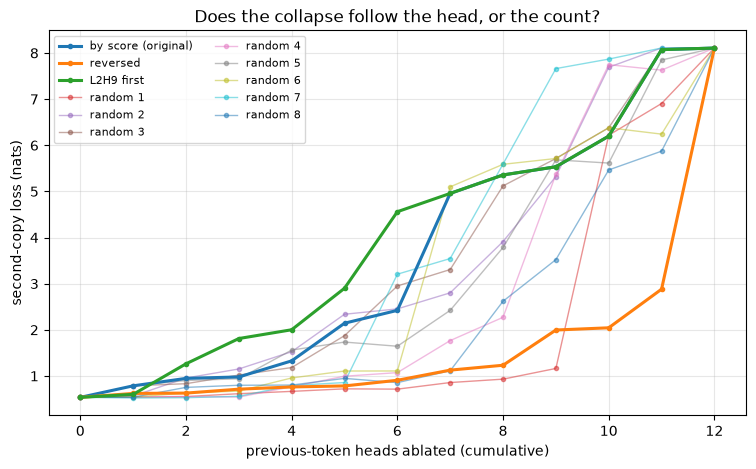

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, L in curves12.items():
    style = dict(lw=2.2, zorder=3) if 'random' not in name else dict(lw=1, alpha=0.5)
    ax.plot(ks12, L, marker='o', ms=3, label=name, **style)
ax.set_xlabel('previous-token heads ablated (cumulative)')
ax.set_ylabel('second-copy loss (nats)')
ax.set_title('Does the collapse follow the head, or the count?')
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.show()


**What happened.** The curves overlap. The biggest jump lands anywhere between
k = 6 and k = 12 depending on the ordering, and L2H9 is the head responsible in
one of eleven — the original. Ablated alone it costs +0.065 nats. It was
redundancy exhaustion, not the head.

The result I was not looking for is in the same table: **L4H11 costs +0.250 nats
ablated first and +5.23 nats ablated last.** Same head, same model, factor of
twenty. It is behind the largest jump in five of the eleven orderings.


### 8e. Control 2 — is the 85% interaction real, or is it the logarithm?

Experiment 2 found 85-97% of the joint ablation effect was interaction. But it
measured in **cross-entropy**, which is logarithmic, and log-loss is superadditive
even when the underlying contributions are independent: while enough probability
mass survives on the right token the loss barely moves, and only when it finally
collapses does the loss explode.

This matters because the comparison being drawn is with a biophysical circuit
model where the measured quantity was firing rate — roughly linear — and the
interaction there was ~0. Some of the difference could be the metric rather than
the mechanism.

So repeat the decomposition with two more linear measures, taken from the same
forward pass:

- **probability** of the correct token (bounded, linear in "how much works")
- **centred logit**: `logit(correct) - mean(all logits)`

If the interaction share collapses under these, the 85% was substantially an
artefact of the logarithm. If it holds, it is the circuit.


In [33]:
from math import factorial
import itertools

def metrics_ablated(heads, mode='zero'):
    """loss, mean p(correct), mean centred logit -- all on second-copy positions."""
    if heads:
        with model.hooks(fwd_hooks=build(heads, mode)):
            lg = model(tokens)
    else:
        lg = model(tokens)
    # logits[:, i] predicts tokens[:, i+1]
    sl  = lg[:, SEQ_LEN:2*SEQ_LEN, :]
    tgt = tokens[:, SEQ_LEN+1:2*SEQ_LEN+1]
    correct = sl.gather(-1, tgt.unsqueeze(-1)).squeeze(-1)
    logprobs = sl.log_softmax(-1).gather(-1, tgt.unsqueeze(-1)).squeeze(-1)
    return {
        'loss':          (-logprobs).mean().item(),
        'probability':   logprobs.exp().mean().item(),
        'centred logit': (correct - sl.mean(-1)).mean().item(),
    }

base_m = metrics_ablated([])
print('clean:', {k: round(v, 4) for k, v in base_m.items()})


clean: {'loss': 0.5362, 'probability': 0.876, 'centred logit': 21.1282}


In [34]:
subsets = [frozenset(c) for n in range(len(IND_HEADS)+1)
                       for c in itertools.combinations(IND_HEADS, n)]

vals = {s: metrics_ablated(sorted(s), 'zero') for s in subsets}

def shapley(v):
    n = len(IND_HEADS); phi = {}
    for head in IND_HEADS:
        others = [h for h in IND_HEADS if h != head]; tot = 0.0
        for sz in range(n):
            w = factorial(sz) * factorial(n - sz - 1) / factorial(n)
            for c in itertools.combinations(others, sz):
                s = frozenset(c)
                tot += w * (v[s | {head}] - v[s])
        phi[head] = tot
    return phi

summary = {}
for m in ['loss', 'probability', 'centred logit']:
    sign = 1.0 if m == 'loss' else -1.0        # damage is positive for all three
    dmg = {s: sign * (vals[s][m] - base_m[m]) for s in subsets}
    total = dmg[frozenset(IND_HEADS)]
    marg  = sum(dmg[frozenset([h])] for h in IND_HEADS)
    phi   = shapley(dmg)
    summary[m] = {'total': total, 'marginal': marg,
                  'interaction': total - marg,
                  'share': (total - marg) / total,
                  'shapley_sum': sum(phi.values()), 'phi': phi}

print(f"{'metric':<16}{'joint':>10}{'sum marg':>11}{'interaction':>13}{'share':>9}")
for m, d in summary.items():
    print(f"{m:<16}{d['total']:>10.4f}{d['marginal']:>11.4f}"
          f"{d['interaction']:>13.4f}{100*d['share']:>8.1f}%")
print()
for m, d in summary.items():
    assert abs(d['shapley_sum'] - d['total']) < 1e-6, m
print('efficiency axiom holds for all three metrics')


metric               joint   sum marg  interaction    share
loss                4.7872     0.6956       4.0916    85.5%
probability         0.6127     0.3327       0.2800    45.7%
centred logit       9.0038     6.9178       2.0860    23.2%

efficiency axiom holds for all three metrics


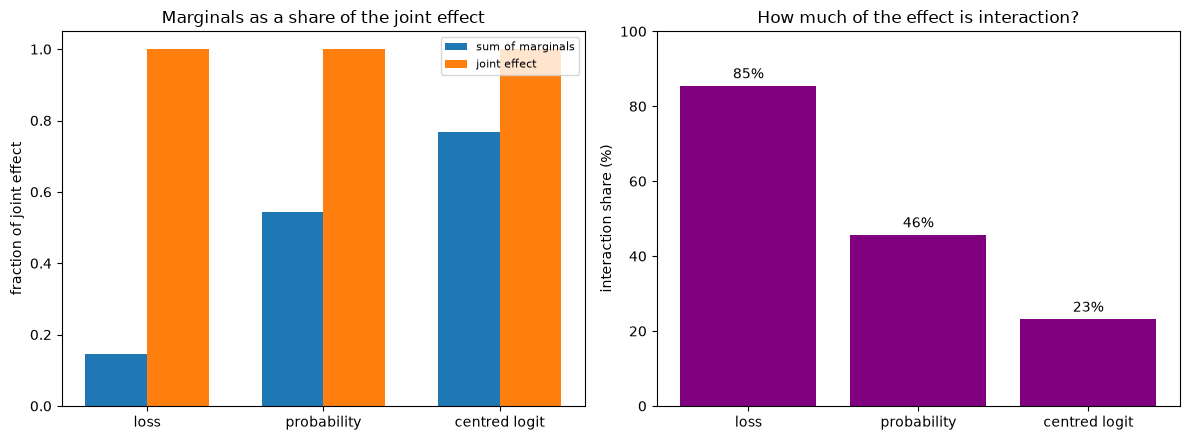

In [35]:
ms = list(summary)
x = np.arange(len(ms)); w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(x - w/2, [summary[m]['marginal'] / summary[m]['total'] for m in ms], w,
            label='sum of marginals')
axes[0].bar(x + w/2, [1.0]*len(ms), w, label='joint effect')
axes[0].set_xticks(x); axes[0].set_xticklabels(ms)
axes[0].set_ylabel('fraction of joint effect')
axes[0].set_title('Marginals as a share of the joint effect')
axes[0].legend(fontsize=8)

axes[1].bar(x, [100*summary[m]['share'] for m in ms], color='purple')
axes[1].set_xticks(x); axes[1].set_xticklabels(ms)
axes[1].set_ylabel('interaction share (%)'); axes[1].set_ylim(0, 100)
axes[1].set_title('How much of the effect is interaction?')
for i, m in enumerate(ms):
    axes[1].text(i, 100*summary[m]['share'] + 2, f"{100*summary[m]['share']:.0f}%",
                 ha='center')

plt.tight_layout(); plt.show()


**What happened.** The interaction share falls from **85.5%** under cross-entropy
to **45.7%** under probability to **23.2%** under the centred logit. The
efficiency axiom holds for all three, so each decomposition is internally
correct — what changes is what is being decomposed.

The interaction is real: 23% is still a long way from the ~0% found in the
biophysical circuit model. But the 85% headline was substantially a property of
measuring in log space, and this control should have been run before experiment 2
was written up. The README and NOTES have been corrected.


### What happened

**The prediction failed.** Under zero ablation L4H11 costs +0.250 nats against
+0.612 for the most damaging single induction head. Less, not more. It is not a
bottleneck.

Two things survive the failure:

- **The causal link is real and specific.** Induction scores drop with L4H11
  removed (L5H1 0.889 -> 0.537, L5H5 0.907 -> 0.673, L7H2 0.814 -> 0.672) while
  the control head moves none of them by more than 0.01. L4H11 does feed the
  induction heads. It is simply replaceable.
- **The counterfactual reverses the ranking again.** Under resample L4H11 costs
  +0.736 against +0.116 for the best single induction head, the opposite
  ordering to zero ablation.

If the previous-token role is redundant, the way to find out is to remove more of
it. That is 8b.


## 9. The limit of everything above

This whole notebook measures **where each head looks**. It says nothing about
whether the model *uses* what the head brings back.

Those turn out to be different properties. In experiment 2, L5H5, the head with
the highest score here ,Çcan be ablated with almost no effect on the loss.
Attention placement is correlational. Ablation is the causal measure.

That is what `02_ablation_shapley.py` is for.
